In [2]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
# import plot_toe_eddies as plot
import class_EDDIES as ed
import pandas as pd
from pathlib import Path

In [ ]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return f"{hours}h {minutes:02d}m"


def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20
        )

In [ ]:
date = '2026-07-04'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]

station_1 = (dm_to_dd(16, 38.247), dm_to_dd(34, 29.976, True))
station_2 = (dm_to_dd(15, 25.675), dm_to_dd(34, 29.963, True))
station_3 = (dm_to_dd(11, 38.167), dm_to_dd(37, 24.128, True))
station_4 = (dm_to_dd(11,57.498), dm_to_dd(38, 9.637, True))
station_5 = (dm_to_dd(11,53.235), dm_to_dd(39, 12.933, True))
station_6 = (dm_to_dd(11,32.443), dm_to_dd(38, 28.558, True))
station_7 = (dm_to_dd(11,39.051), dm_to_dd(39, 23.478, True))
# station_8 = (dm_to_dd(11,38.575), dm_to_dd(39, 23.533, True))

glider1 = (11.54, -37.41) # 283 and 284 have been deployed
#284(microrider) 01-07-2026 @ 11:30 UTC -37.4138 11.6210

#283(suna) 03-07-2026 @ 11:31 UTC -38.4683 11.5483

In [5]:
station_3

(11.636116666666666, -37.40213333333333)

In [6]:
# stations = np.array([
#     station_1,
#     station_2,
#     station_3,
#     station_4,
#     station_5,
#     station_6,
#     station_7,
#     station_8
# ])

# # -------------------------
# # Create Dataset
# # -------------------------
# ds = xr.Dataset(
#     data_vars=dict(
#         station_lon=("station", stations[:, 0]),
#         station_lat=("station", stations[:, 1]),
#         glider_lon=((), glider1[0]),
#         glider_lat=((), glider1[1]),
#     ),
#     coords=dict(
#         station=np.arange(1, 9),
#     ),
#     attrs=dict(
#         title="CTD station locations and glider deployment",
#         description="Station coordinates and glider deployment position",
#     ),
# )

# # Add units
# ds.station_lon.attrs["units"] = "degrees_east"
# ds.station_lat.attrs["units"] = "degrees_north"
# ds.glider_lon.attrs["units"] = "degrees_east"
# ds.glider_lat.attrs["units"] = "degrees_north"

# # -------------------------
# # Save to NetCDF
# # -------------------------
# output_file = "ctd_stations_glider.nc"
# ds.to_netcdf(output_file)

# print(f"Saved to {output_file}")

In [7]:
##### POSITION VARIABLES #####
ft=10
small_box = False
if small_box is True:
    lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
    pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
    vmin_adt = -0.2
    vmax_adt = 1.2
    title="zoom"
else:
    lon_min, lon_max, lat_min, lat_max = 6, 23, -40, -33
    pos_west,pos_east,pos_south,pos_north  = 6, 23, -40,-33  #Reset the area
    title=""
    vmin_adt = -0.25
    vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [ ]:
dir = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/"
date_sst = '2026-07-04'
sst_path = dir + f"Eddies/{date}/sst/BT_masked_Meteosat_{date.replace("-", "")}T01.nc"
dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
save_fig = dir + f"daily_figures/{date}/"
if not os.path.isdir(save_fig):
    os.makedirs(save_fig)

fname_bathy = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/bathymetry/etopo2.nc"
ctd_path = "/Volumes/science/MD252_WHIRLS/CTD/data/"

date_adt="2026-07-01"
adt_path= f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date_adt}/ssh/{date_adt}_cmems_data.nc"


In [9]:
adt_data = nc.Dataset(adt_path)
# adt_data = lst_adt_data[0]

In [10]:
lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_94820/1840043835.py:7: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [11]:
sst_data = xr.open_dataset(sst_path)
lats_sst = sst_data['lat']
lons_sst = sst_data['lon']
# time = sst_data['time']
sst = sst_data['BT_masked']

sst = np.where(sst==np.nan, 0, sst)

In [ ]:
path_nav = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [13]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [14]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

In [15]:
files = os.listdir(dir_eddies)
for fname in files:
    if "anti" in fname:
        if "maxspeed" in fname:
            gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdf_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdf_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")
    else:
        if "maxspeed" in fname:
            gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdfcyc_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdfcyc_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")


In [ ]:
speed_knots = 6.0
stop_hours = 2.0

points = [
    (ship_x, ship_y),
    (s1_x, s1_y),
    (s2_x, s2_y),
    (s3_x, s3_y),
]

total_time = 0.0
times = []  # cumulative arrival times

for i in range(1, len(points)):
    lon1, lat1 = points[i-1]
    lon2, lat2 = points[i]

    dist_nm = haversine_nm(lon1, lat1, lon2, lat2)
    travel_time = dist_nm / speed_knots  # hours

    total_time += travel_time

    # arrival at point i
    times.append(total_time)

    # add stop time except after final point
    if i < len(points) - 1:
        total_time += stop_hours

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


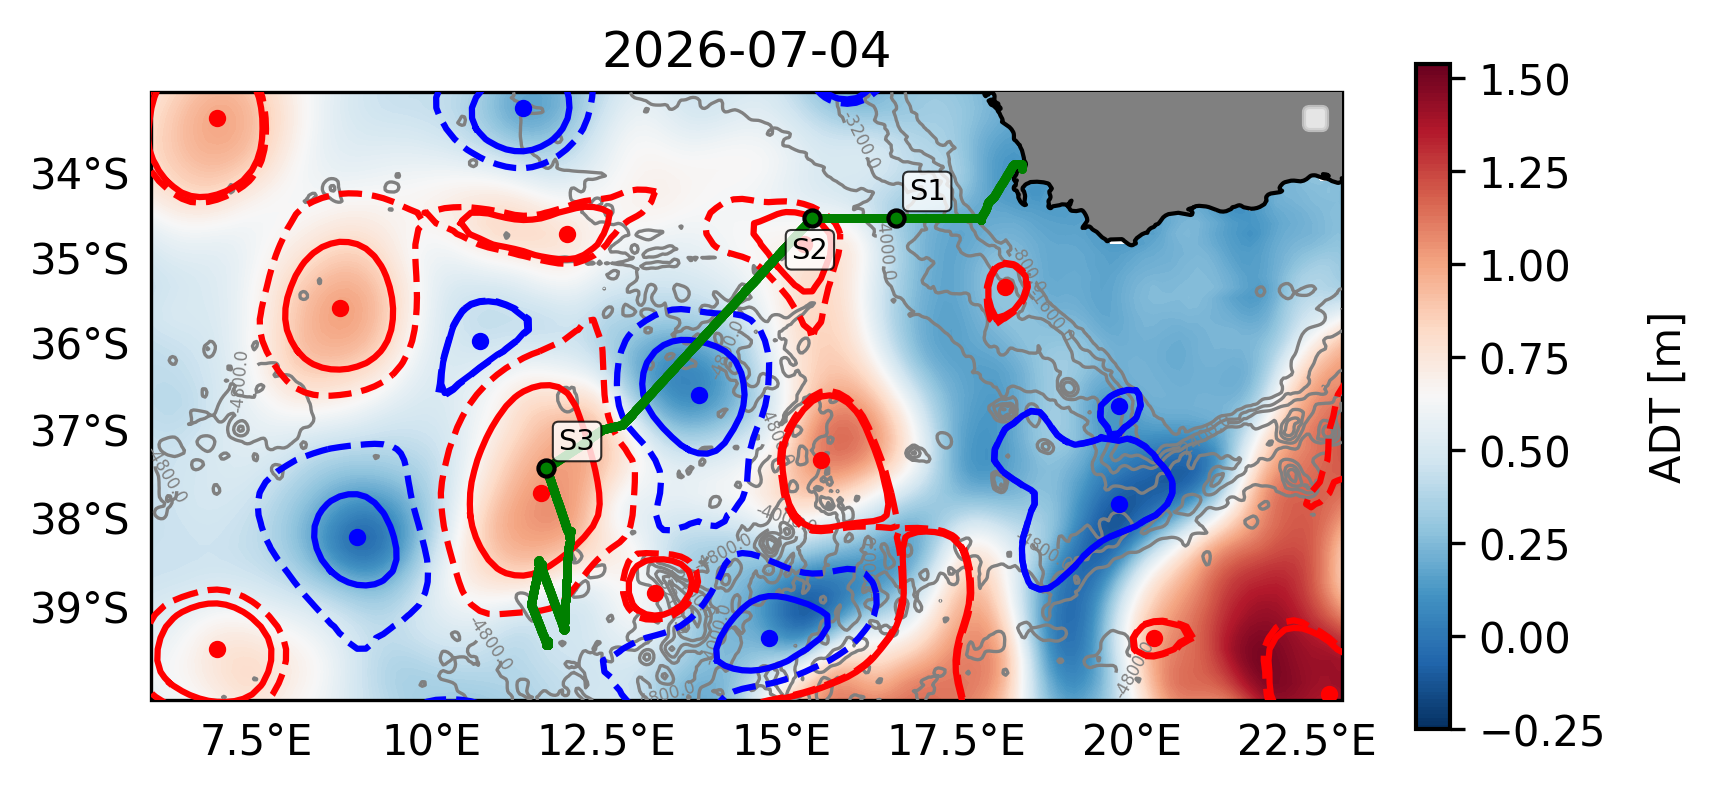

In [29]:
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
# Q = ax0.quiver(
#     lon_2D[::step, ::step],
#     lat_2D[::step, ::step],
#     ugos[::step, ::step],
#     vgos[::step, ::step],
#     transform=crs,
#     scale=18, zorder=8)
# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)

# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
stations = [station_1, station_2, station_3]
for i in range(len(stations)):
    x, y = stations[i]

    ax0.scatter(
        x, y,
        s=15,
        color='green',
        edgecolors='black',
        zorder=100,
        transform=crs
    )


    if i == 1:
        ax0.annotate(
            f"S{i+1}",
            xy=(x, y),
            xycoords=crs,
            xytext=(4, -11),  # left + up offset
            textcoords='offset points',
            fontsize='x-small',
            color='black',
            ha='right',
            va='bottom',
            zorder=102,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.5,
                alpha=0.8
            )
        )
    else:
        ax0.annotate(
        f"S{i+1}",
        xy=(x, y),
        xycoords=crs,
        xytext=(3, 3),  # <-- offset in points (RIGHT, UP)
        textcoords='offset points',
        fontsize='x-small',
        color='black',
        ha='left',
        va='bottom',
        zorder=101,
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.8
        )
    )


arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
# ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}_ctd.png")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


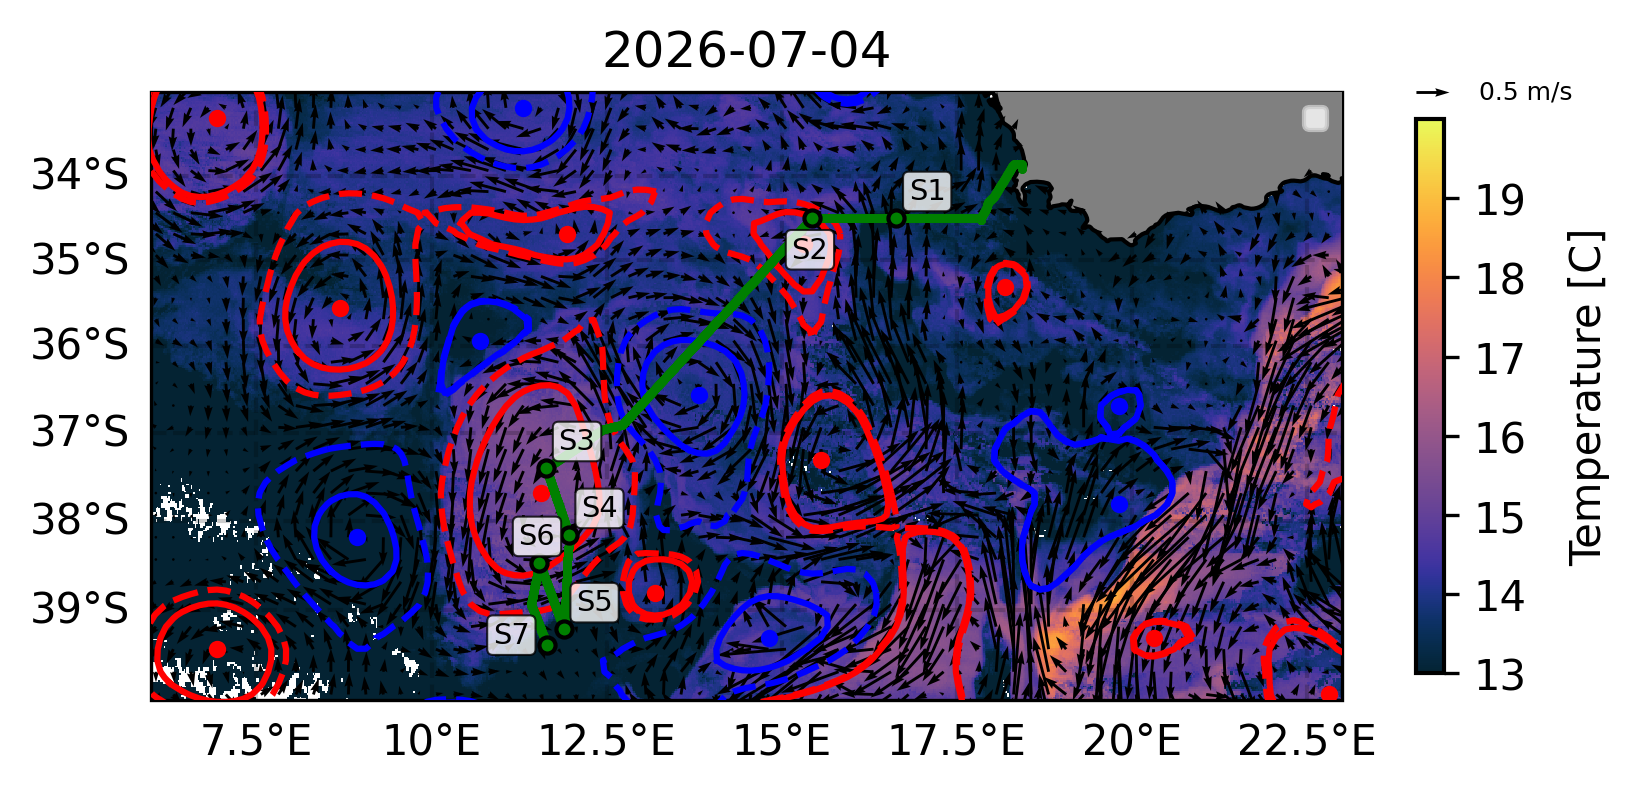

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
# bathy_contours = np.arange(-5500, 0, 700)
# c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
# ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
c2 = ax0.pcolormesh(lon2d, lat2d, sst[:,:], vmin=13, vmax=20, cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.5)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(13, 20, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
stations = [station_1, station_2, station_3, station_4, station_5, station_6, station_7]
for i in range(len(stations)):
    x, y = stations[i]

    ax0.scatter(
        x, y,
        s=15,
        color='green',
        edgecolors='black',
        zorder=100,
        transform=crs
    )


    if i == 1:
        ax0.annotate(
            f"S{i+1}",
            xy=(x, y),
            xycoords=crs,
            xytext=(4, -11),  # left + up offset
            textcoords='offset points',
            fontsize='x-small',
            color='black',
            ha='right',
            va='bottom',
            zorder=102,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.5,
                alpha=0.8
            )
        )
    elif i == 5:
        ax0.annotate(
            f"S{i+1}",
            xy=(x, y),
            xycoords=crs,
            xytext=(-5, 3),  # left + up offset
            textcoords='offset points',
            fontsize='x-small',
            color='black',
            ha='left',
            va='bottom',
            zorder=102,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.5,
                alpha=0.8
            )
        )
    elif i == 6:
        ax0.annotate(
            f"S{i+1}",
            xy=(x, y),
            xycoords=crs,
            xytext=(-13, -1),    # left + up offset
            textcoords='offset points',
            fontsize='x-small',
            color='black',
            ha='left',
            va='bottom',
            zorder=102,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.5,
                alpha=0.8
            )
        )
    else:
        ax0.annotate(
        f"S{i+1}",
        xy=(x, y),
        xycoords=crs,
        xytext=(3, 3),  # <-- offset in points (RIGHT, UP)
        textcoords='offset points',
        fontsize='x-small',
        color='black',
        ha='left',
        va='bottom',
        zorder=101,
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.8
        )
    )

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
ax0.quiverkey(
        Q,
        X=1.09,
        Y=1,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 6},
        labelpos="E",
        color="black"
    )

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_sst_{title}_ctd.png")

In [37]:
import xarray as xr

ctd = xr.open_dataset("ctd_metadata.nc")

In [25]:
ctd.close()

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_94820/1257909700.py:71: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for i in range(ctd.dims["cast"]):
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


16.63745 -34.4996
15.427916666666667 -34.499383333333334
11.636116666666666 -37.40213333333333
11.9583 -38.16061666666667
11.88725 -39.21555
11.540716666666667 -38.475966666666665
11.65085 -39.3913
11.63765 -39.333333333333336
11.6432 -39.29548333333334


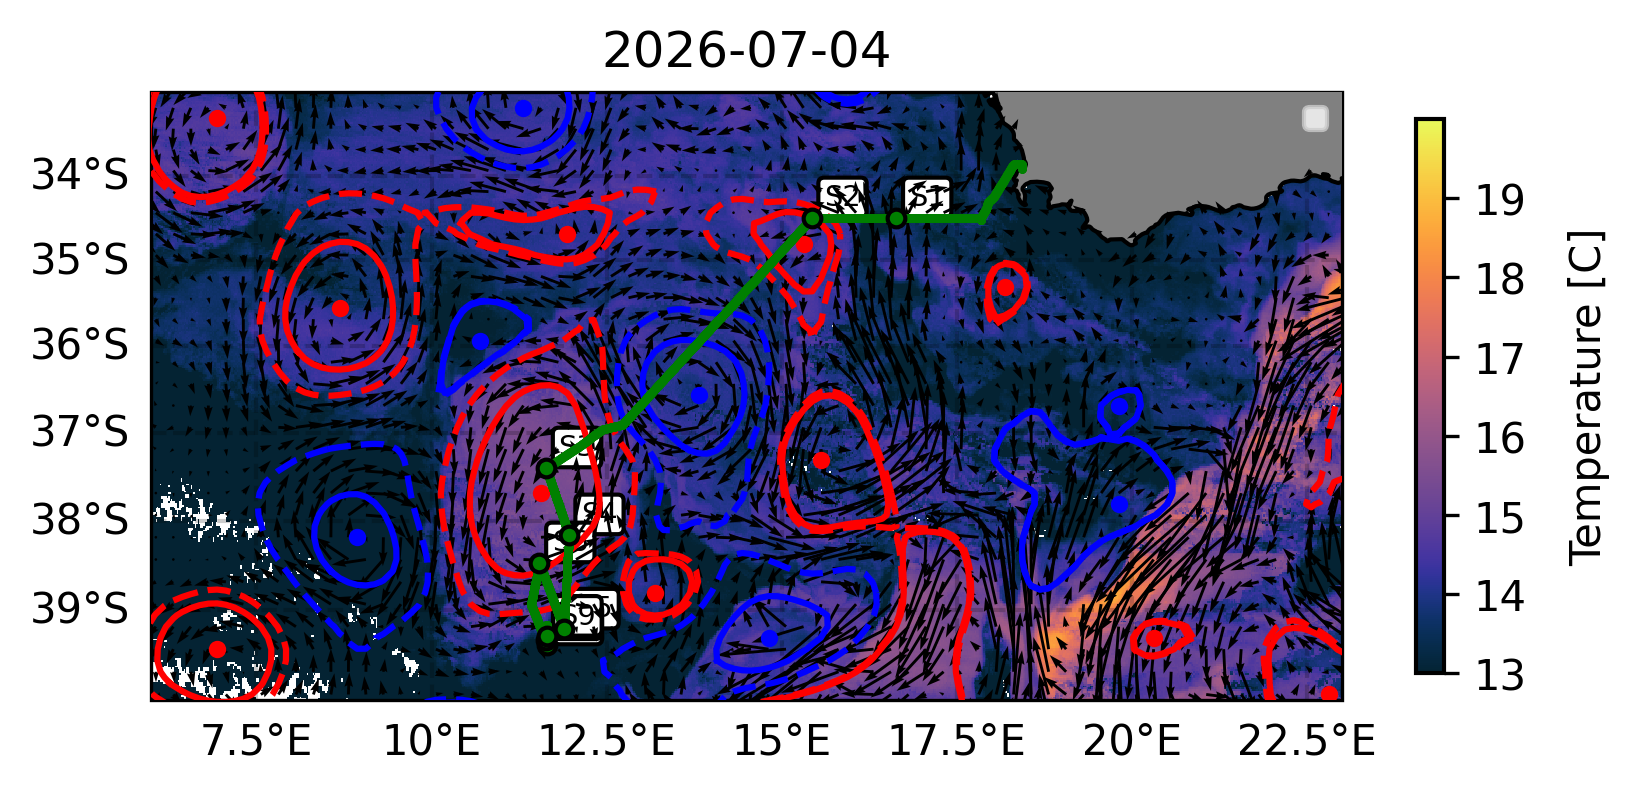

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
# bathy_contours = np.arange(-5500, 0, 700)
# c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
# ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
c2 = ax0.pcolormesh(lon2d, lat2d, sst[:,:], vmin=13, vmax=20, cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.5)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(13, 20, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)

plotted = set()

for i in range(ctd.dims["cast"]):

    station = int(ctd.station_number.isel(cast=i))

    if station in plotted:
        continue

    plotted.add(station)

    lon = float(ctd.lon_start.isel(cast=i))
    lat = float(ctd.lat_start.isel(cast=i))
    print(lon, lat)

    ax0.scatter(
        lon,
        lat,
        s=18,
        color="green",
        edgecolors="black",
        transform=crs,
        zorder=100,
    )

    ax0.annotate(
        f"S{station}",
        xy=(lon, lat),
        xycoords=crs,
        xytext=(3, 3),
        textcoords="offset points",
        fontsize="x-small",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black",))
           

ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_sst_{title}_ctd.png")

In [ ]:
ctd = xr.open_dataset("/Volumes/science/MD252_WHIRLS/CTD/ctd_metadata.nc")
ctd

<xarray.Dataset> Size: 2kB
Dimensions:         (cast: 19)
Coordinates:
  * cast            (cast) int64 152B 0 1 2 3 4 5 6 7 ... 12 13 14 15 16 17 18
    station_id      (cast) <U2 152B ...
    time_start      (cast) datetime64[ns] 152B ...
    time_end        (cast) datetime64[ns] 152B ...
    date            (cast) <U8 608B ...
Data variables:
    station_number  (cast) int64 152B ...
    cast_id         (cast) int64 152B ...
    depth           (cast) float64 152B ...
    lon_start       (cast) float64 152B ...
    lat_start       (cast) float64 152B ...
    lon_end         (cast) float64 152B ...
    lat_end         (cast) float64 152B ...

In [31]:
ctd["station_id"].values

array(['1a', '1a', '2a', '3a', '3b', '4a', '4b', '5a', '5b', '6a', '7a',
       '7b', '7c', '7d', '8a', '8b', '9a', '9b', '9c'], dtype='<U2')

In [33]:
ctd["cast_id"].values

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19])

In [35]:
ctd["station_number"].values

array([1, 1, 2, 3, 3, 4, 4, 5, 5, 6, 7, 7, 7, 7, 8, 8, 9, 9, 9])

In [36]:
ctd.close()

In [24]:
ds.close()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


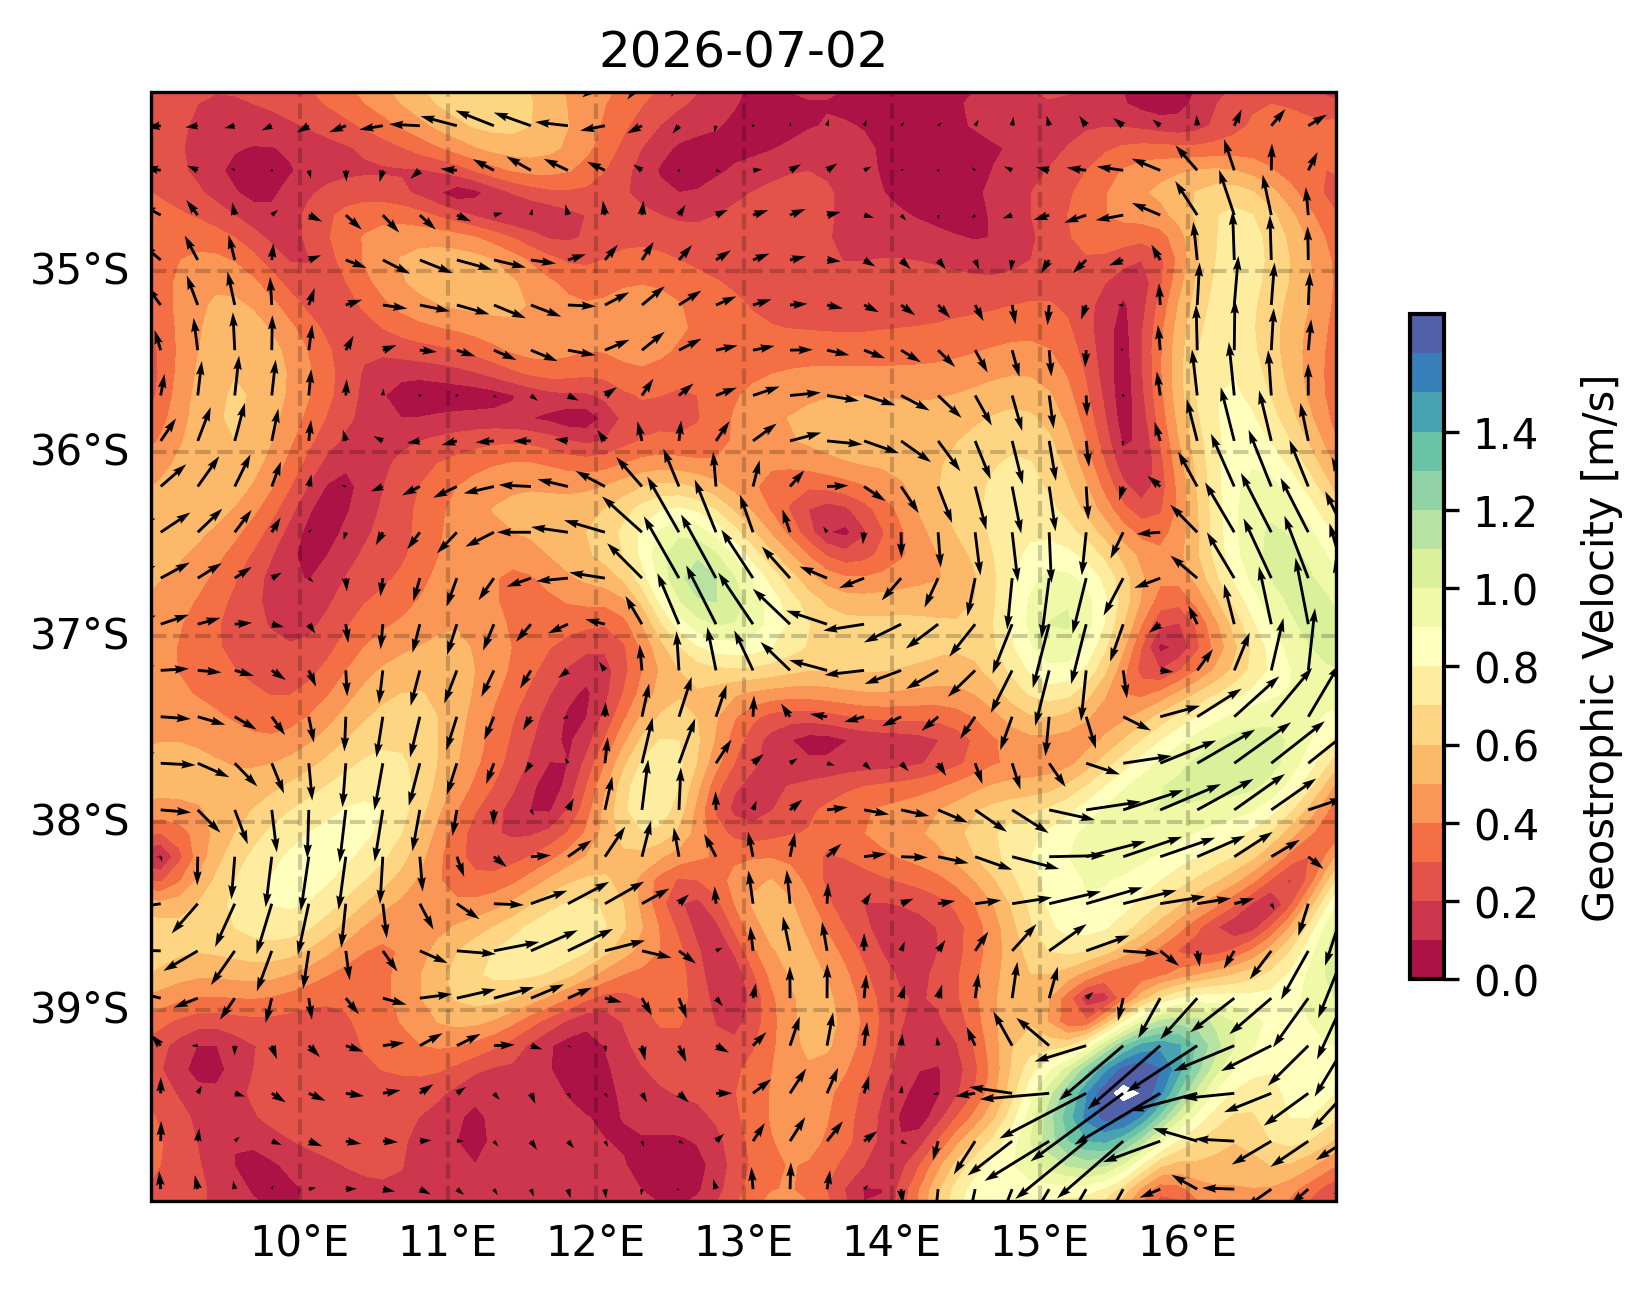

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

c2 = ax0.contourf(lons, lats, current_mag,  levels=np.arange(0, 1.8, 0.1), cmap='Spectral',
            transform=crs, linestyles='dashed', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(0, 1.6, 0.2))
cbar.set_label('Geostrophic Velocity [m/s]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

In [89]:
current_mag.shape

(156, 180)

In [ ]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="Current Position")
ax0.scatter(s1_x, s1_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s1_x, s1_y}")
ax0.scatter(s2_x, s2_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s2_x, s2_y}")
ax0.scatter(s3_x, s3_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s3_x, s3_y}")
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, label="MD Track", color='black', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}.png")